# Truck Operator Super-App — Product Analytics

**Context.** A truck-operator super-app (modelled on platforms like BlackBuck) sells FASTag tolling, fuel payments, GPS telematics and a freight-load marketplace to Indian truck operators. As its product analyst, I answer five questions:

1. **Activation:** where do new operators drop out of onboarding, and who drops most?
2. **Retention:** how well do operators stay, and what predicts staying?
3. **Cross-sell:** how much is a second service worth?
4. **Root cause:** why did successful FASTag recharges fall sharply in mid-August 2026?
5. **Experiment:** should we launch auto-recharge to everyone, based on the September A/B test?

**Data.** A **simulated** dataset of 40,000 operators (Jan 2025 – Oct 2026 signups; activity reported Jan–Oct 2026), generated by `scripts/01_generate_data.py`. It is synthetic, but built to behave like a real two-sided trucking platform: seasonal monsoon dips, a bank outage, cross-sell effects and an experiment. Revenue uses assumed take rates (toll 0.4%, fuel 0.6%, ₹300 per GPS device per month, ₹150 per load booked).

## 1. Setup

In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "images"; IMG.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})

con = sqlite3.connect(ROOT / "data" / "superapp.db")
ops = pd.read_sql("SELECT * FROM operators", con, parse_dates=["signup_ts", "second_service_ts"])
ev = pd.read_sql("SELECT * FROM onboarding_events", con, parse_dates=["event_ts"])
act = pd.read_sql("SELECT * FROM monthly_activity", con)
rc = pd.read_sql("SELECT * FROM fastag_recharges", con, parse_dates=["recharge_ts"])
ab = pd.read_sql("SELECT * FROM ab_test_assignments", con)
act = act.merge(ops[["operator_id", "city", "fleet_band", "acquisition_channel", "trucks"]], on="operator_id")
act["services"] = 1 + (act.fuel_spend > 0).astype(int) + (act.gps_devices > 0).astype(int) + (act.loads_booked > 0).astype(int)
for name, df in [("operators", ops), ("onboarding_events", ev), ("monthly_activity", act), ("fastag_recharges", rc), ("ab_test", ab)]:
    print(f"{name:<18}{len(df):>9,} rows")

operators            40,000 rows
onboarding_events   144,306 rows
monthly_activity     96,211 rows
fastag_recharges    775,864 rows
ab_test              10,978 rows


## 2. Monthly health: the North Star view

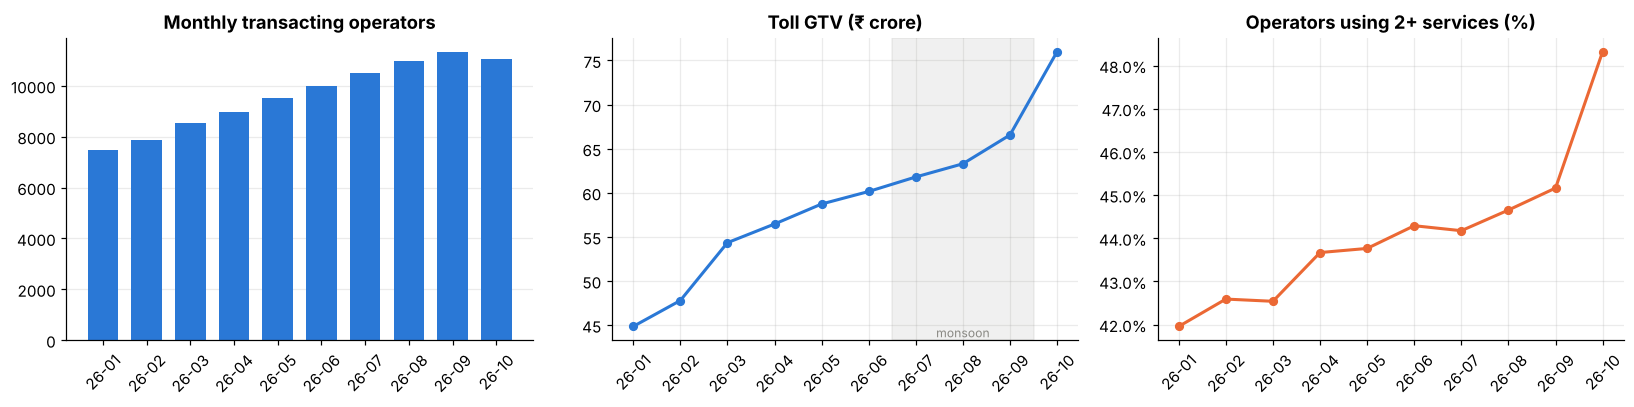

month,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
transacting_operators,7460.00,7889.00,8545.00,8979.00,9517.00,9982.00,10497.00,10978.00,11317.00,11047.00
toll_gtv_cr,44.85,47.79,54.34,56.46,58.73,60.15,61.80,63.29,66.56,76.00
net_revenue_lakh,90.25,98.98,109.92,116.00,123.61,128.25,132.42,136.94,143.06,160.16
arpu,1210.00,1255.00,1286.00,1292.00,1299.00,1285.00,1261.00,1247.00,1264.00,1450.00
multi_pct,42.00,42.60,42.50,43.70,43.80,44.30,44.20,44.70,45.20,48.30


In [2]:
kpi = act.groupby("month").agg(transacting_operators=("operator_id", "count"), toll_gtv=("toll_gtv", "sum"),
                               net_revenue=("net_revenue", "sum"), multi=("services", lambda s: (s >= 2).mean()))
kpi["arpu"] = kpi.net_revenue / kpi.transacting_operators
kpi["multi_service_operators"] = (kpi.multi * kpi.transacting_operators).round()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
x = [m[2:] for m in kpi.index]
axes[0].bar(x, kpi.transacting_operators, color=BLUE, width=0.7); axes[0].set_title("Monthly transacting operators")
axes[1].plot(x, kpi.toll_gtv / 1e7, color=BLUE, lw=2, marker="o", ms=5); axes[1].set_title("Toll GTV (₹ crore)")
axes[1].axvspan(5.5, 8.5, color=GREY, alpha=0.12); axes[1].text(7, axes[1].get_ylim()[0], "monsoon", ha="center", va="bottom", color=GREY, fontsize=8)
axes[2].plot(x, kpi.multi * 100, color=ORANGE, lw=2, marker="o", ms=5); axes[2].set_title("Operators using 2+ services (%)")
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter())
for ax in axes: ax.tick_params(axis="x", rotation=45)
axes[0].grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(IMG / "01_monthly_kpis.png", bbox_inches="tight"); plt.show()
kpi.assign(toll_gtv_cr=(kpi.toll_gtv / 1e7).round(2), net_revenue_lakh=(kpi.net_revenue / 1e5).round(2),
           multi_pct=(kpi.multi * 100).round(1), arpu=kpi.arpu.round(0))[
    ["transacting_operators", "toll_gtv_cr", "net_revenue_lakh", "arpu", "multi_pct"]].T

**Proposed North Star metric: monthly multi-service operators** (operators transacting on 2+ services in a month). It captures both reach (operators) and depth (cross-sell), and, as sections 4–5 show, multi-service operators churn about a third as often and earn over 10× the revenue per month (assumed take rates). Toll GTV is a useful input metric, but it moves with the monsoon and with bank outages, so it is a poor single target.

## 3. Activation: the onboarding funnel

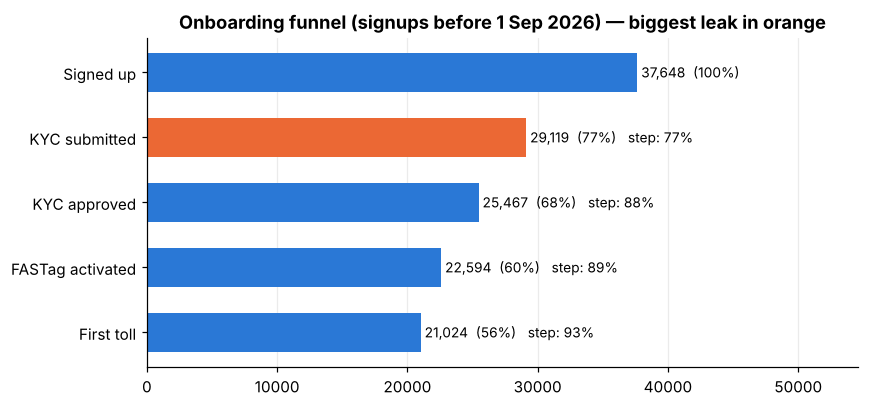

,stage,operators,pct_of_signups,step_conversion,dropped
0,Signed up,37648,100.0,NaN,NaN
1,KYC submitted,29119,77.3,77.3,8529.0
2,KYC approved,25467,67.6,87.5,3652.0
3,FASTag activated,22594,60.0,88.7,2873.0
4,First toll,21024,55.8,93.1,1570.0


In [3]:
STAGES = ["signup", "kyc_submitted", "kyc_approved", "fastag_activated", "first_toll"]
LABELS = ["Signed up", "KYC submitted", "KYC approved", "FASTag activated", "First toll"]
mature = ops[ops.signup_ts < "2026-09-01"].operator_id
reached = ev[ev.operator_id.isin(mature)].groupby("stage").operator_id.nunique().reindex(STAGES)
funnel = pd.DataFrame({"stage": LABELS, "operators": reached.values})
funnel["pct_of_signups"] = (funnel.operators / funnel.operators.iloc[0] * 100).round(1)
funnel["step_conversion"] = (funnel.operators / funnel.operators.shift() * 100).round(1)
funnel["dropped"] = (funnel.operators.shift() - funnel.operators)

fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(funnel))[::-1]
worst = funnel.dropped.idxmax()
ax.barh(y, funnel.operators, color=[ORANGE if i == worst else BLUE for i in funnel.index], height=0.6)
for yi, (_, r) in zip(y, funnel.iterrows()):
    lab = f"{int(r.operators):,}  ({r.pct_of_signups:.0f}%)"
    if pd.notna(r.step_conversion): lab += f"   step: {r.step_conversion:.0f}%"
    ax.text(r.operators + 300, yi, lab, va="center", fontsize=9)
ax.set_yticks(y, funnel.stage); ax.set_xlim(0, funnel.operators.max() * 1.45)
ax.set_title("Onboarding funnel (signups before 1 Sep 2026) — biggest leak in orange"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(IMG / "02_onboarding_funnel.png", bbox_inches="tight"); plt.show()
funnel

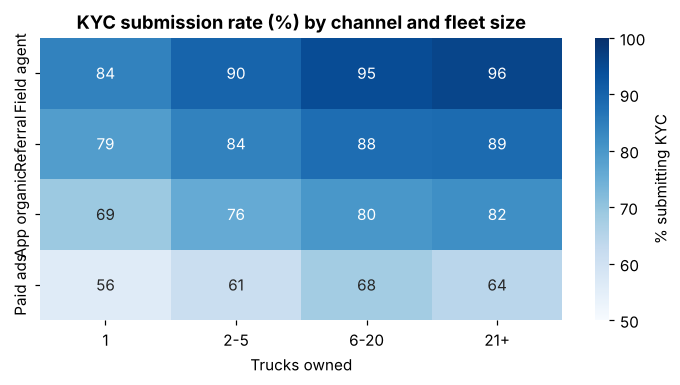

,mean,size
acquisition_channel,,
Paid ads,60.6,9307
App organic,74.2,9415
Referral,83.0,5590
Field agent,88.9,13336


In [4]:
kyc = ops[ops.signup_ts < "2026-09-01"].copy()
kyc["kyc_submitted"] = kyc.operator_id.isin(ev[ev.stage == "kyc_submitted"].operator_id)
grid = kyc.pivot_table(index="acquisition_channel", columns="fleet_band", values="kyc_submitted", aggfunc="mean") * 100
grid = grid.reindex(index=["Field agent", "Referral", "App organic", "Paid ads"], columns=["1", "2-5", "6-20", "21+"])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.heatmap(grid, annot=True, fmt=".0f", cmap="Blues", vmin=50, vmax=100, cbar_kws={"label": "% submitting KYC"}, ax=ax)
ax.set_title("KYC submission rate (%) by channel and fleet size"); ax.set_xlabel("Trucks owned"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(IMG / "03_kyc_by_segment.png", bbox_inches="tight"); plt.show()
by_ch = kyc.groupby("acquisition_channel").kyc_submitted.agg(["mean", "size"]); by_ch["mean"] = (by_ch["mean"] * 100).round(1)
by_ch.sort_values("mean")

**Finding.** KYC submission is the biggest leak: **about 1 in 4 signups never submit KYC**, more than the next three steps combined. It is worst for **paid-ads signups with a single truck (56%)** and best for **field-agent signups (84–96%)**, where an agent helps with documents.

**Recommendation.** Offer assisted KYC (agent call-back or a touchpoint visit) to paid-ads and single-truck signups within 24 hours of signup. A/B test the call-back, using KYC submission within 7 days as the primary metric.

## 4. Retention

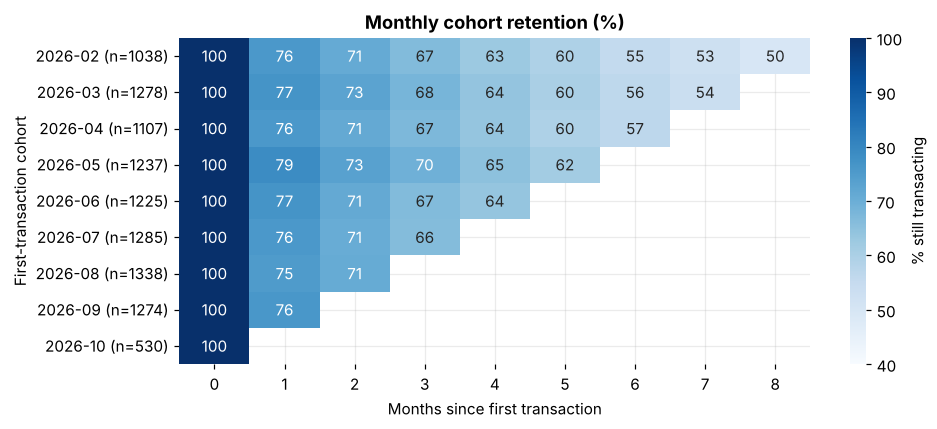

Average month-1 retention: 76.4 %  | month-3: 67.4 %


In [5]:
act["mi"] = act.month.str[:4].astype(int) * 12 + act.month.str[5:7].astype(int)
first = act.groupby("operator_id").mi.min().rename("cohort_mi")
a = act.join(first, on="operator_id"); a["k"] = a.mi - a.cohort_mi
LAST = 2026 * 12 + 10
coh = a[a.cohort_mi > 2026 * 12 + 1].pivot_table(index="cohort_mi", columns="k", values="operator_id", aggfunc="nunique")
ret = coh.divide(coh[0], axis=0) * 100
ret.index = [f"{(i - 1) // 12}-{(i - 1) % 12 + 1:02d}" for i in ret.index]
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(ret, annot=True, fmt=".0f", cmap="Blues", vmin=40, vmax=100, ax=ax, cbar_kws={"label": "% still transacting"},
            yticklabels=[f"{i} (n={int(n)})" for i, n in zip(ret.index, coh[0])])
ax.set_title("Monthly cohort retention (%)"); ax.set_xlabel("Months since first transaction"); ax.set_ylabel("First-transaction cohort")
plt.tight_layout(); plt.savefig(IMG / "04_cohort_retention.png", bbox_inches="tight"); plt.show()
print("Average month-1 retention:", round(ret[1].mean(), 1), "%  | month-3:", round(ret[3].dropna().mean(), 1), "%")

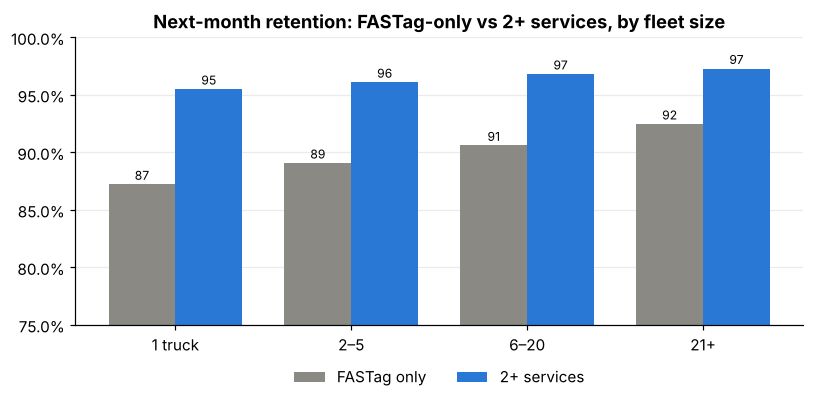

Monthly churn — FASTag only: 11.2 % | 2+ services: 3.7 %


In [6]:
nxt = act[["operator_id", "mi"]].assign(next_active=1)
cur = act[act.month <= "2026-09"].merge(nxt.assign(mi=nxt.mi - 1), on=["operator_id", "mi"], how="left")
cur["next_active"] = cur.next_active.fillna(0)
cur["segment"] = np.where(cur.services >= 2, "2+ services", "FASTag only")
seg = cur.groupby(["segment", "fleet_band"]).next_active.mean().unstack()[["1", "2-5", "6-20", "21+"]] * 100
overall = cur.groupby("segment").next_active.mean() * 100

fig, ax = plt.subplots(figsize=(7.5, 3.8))
xs = np.arange(4); w = 0.38
ax.bar(xs - w / 2, seg.loc["FASTag only"], w, color=GREY, label="FASTag only")
ax.bar(xs + w / 2, seg.loc["2+ services"], w, color=BLUE, label="2+ services")
for i in range(4):
    ax.text(i - w / 2, seg.loc["FASTag only"].iloc[i] + 0.4, f"{seg.loc['FASTag only'].iloc[i]:.0f}", ha="center", fontsize=8)
    ax.text(i + w / 2, seg.loc["2+ services"].iloc[i] + 0.4, f"{seg.loc['2+ services'].iloc[i]:.0f}", ha="center", fontsize=8)
ax.set_xticks(xs, ["1 truck", "2–5", "6–20", "21+"]); ax.set_ylim(75, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax.set_title("Next-month retention: FASTag-only vs 2+ services, by fleet size"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(IMG / "05_retention_multi_service.png", bbox_inches="tight"); plt.show()
monthly_churn = (100 - overall).round(1)
print("Monthly churn — FASTag only:", monthly_churn["FASTag only"], "% | 2+ services:", monthly_churn["2+ services"], "%")

## 5. Cross-sell: what a second service is worth

In [7]:
octm = act[act.month == "2026-10"]
mix = octm.groupby("services").agg(operators=("operator_id", "count"), arpu=("net_revenue", "mean"), revenue=("net_revenue", "sum"))
mix["pct_operators"] = (mix.operators / mix.operators.sum() * 100).round(1)
mix["pct_revenue"] = (mix.revenue / mix.revenue.sum() * 100).round(1)
mix["arpu"] = mix.arpu.round(0)
single_arpu, multi_arpu = mix.loc[1, "arpu"], octm[octm.services >= 2].net_revenue.mean()
expected_life = 1 / (monthly_churn / 100)
ltv = pd.Series({"FASTag only": single_arpu * expected_life["FASTag only"], "2+ services": multi_arpu * expected_life["2+ services"]})
print(f"ARPU: FASTag only ₹{single_arpu:,.0f} vs 2+ services ₹{multi_arpu:,.0f} per month")
print(f"Simple LTV (ARPU / monthly churn): FASTag only ₹{ltv['FASTag only']:,.0f} vs 2+ services ₹{ltv['2+ services']:,.0f}")
mix[["operators", "pct_operators", "arpu", "pct_revenue"]]

ARPU: FASTag only ₹204 vs 2+ services ₹2,782 per month
Simple LTV (ARPU / monthly churn): FASTag only ₹1,821 vs 2+ services ₹75,194


,operators,pct_operators,arpu,pct_revenue
services,,,,
1,5709,51.7,204.0,7.3
2,4014,36.3,2376.0,59.5
3,1324,12.0,4015.0,33.2


**Finding.** Just over half of October's transacting operators use only FASTag, yet they bring in **about 7% of revenue**. Operators with a second service retain much better (section 4) and earn far more per month (assumed take rates). On a simple LTV basis (ARPU ÷ monthly churn), a multi-service operator is worth many times a FASTag-only operator.

**Recommendation.** Make "second service within 60 days of first toll" the activation goal. Prompt fuel payments to small fleets (high fuel spend per truck) and GPS to fleets of 6+ trucks.

## 6. Root cause: the August recharge drop

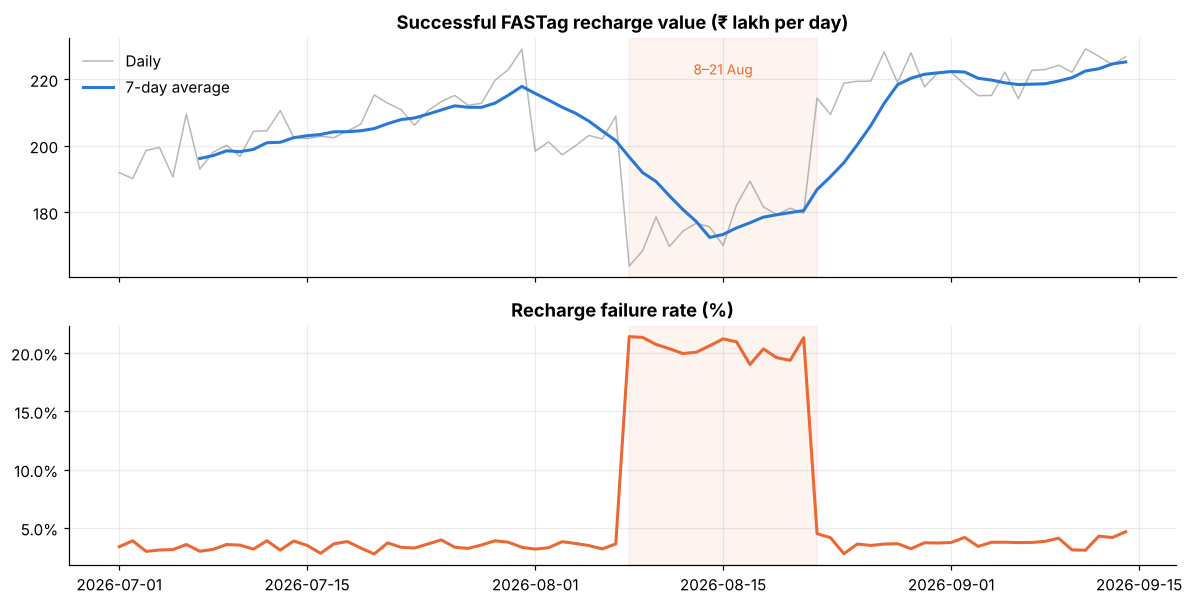

Successful recharge value, 8–21 Aug vs previous 2 weeks: -15.9%  (lost ≈ ₹4.66 crore)
Recharge attempts changed by +1.8% — demand did not fall; payments failed.


In [8]:
rc["date"] = rc.recharge_ts.dt.normalize()
daily = rc[(rc.date >= "2026-07-01") & (rc.date < "2026-09-15")]
d = daily.groupby("date").apply(lambda g: pd.Series({"success_tpv": g.loc[g.status == "success", "amount"].sum(),
                                                     "fail_rate": (g.status == "failed").mean()}))
d["tpv_7d"] = d.success_tpv.rolling(7).mean()
fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
axes[0].plot(d.index, d.success_tpv / 1e5, color=GREY, lw=1, alpha=0.6, label="Daily")
axes[0].plot(d.index, d.tpv_7d / 1e5, color=BLUE, lw=2, label="7-day average")
axes[0].set_title("Successful FASTag recharge value (₹ lakh per day)"); axes[0].legend(frameon=False, loc="upper left")
axes[1].plot(d.index, d.fail_rate * 100, color=ORANGE, lw=2); axes[1].set_title("Recharge failure rate (%)")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
for ax in axes: ax.axvspan(pd.Timestamp("2026-08-08"), pd.Timestamp("2026-08-22"), color=ORANGE, alpha=0.08)
axes[0].text(pd.Timestamp("2026-08-15"), axes[0].get_ylim()[1] * 0.97, "8–21 Aug", ha="center", va="top", color=ORANGE, fontsize=9)
plt.tight_layout(); plt.savefig(IMG / "06_august_drop.png", bbox_inches="tight"); plt.show()

base = rc[(rc.recharge_ts >= "2026-07-25") & (rc.recharge_ts < "2026-08-08")]
inc = rc[(rc.recharge_ts >= "2026-08-08") & (rc.recharge_ts < "2026-08-22")]
b_tpv = base.loc[base.status == "success", "amount"].sum(); i_tpv = inc.loc[inc.status == "success", "amount"].sum()
DROP = (i_tpv - b_tpv) / b_tpv * 100
print(f"Successful recharge value, 8–21 Aug vs previous 2 weeks: {DROP:+.1f}%  (lost ≈ ₹{(b_tpv - i_tpv)/1e7:.2f} crore)")
print(f"Recharge attempts changed by {(len(inc) - len(base)) / len(base) * 100:+.1f}% — demand did not fall; payments failed.")

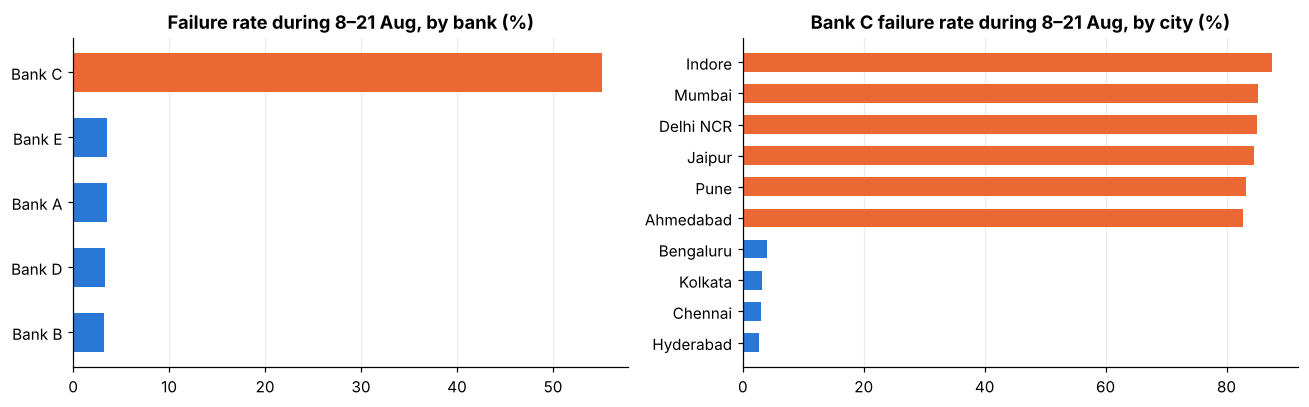

,before,during
bank,,
Bank A,3.5,3.5
Bank B,3.6,3.2
Bank C,3.5,55.1
Bank D,3.8,3.3
Bank E,3.2,3.5


In [9]:
inc = inc.merge(ops[["operator_id", "city"]], on="operator_id"); base = base.merge(ops[["operator_id", "city"]], on="operator_id")
cut = pd.DataFrame({"before": base.groupby("bank").status.apply(lambda s: (s == "failed").mean() * 100),
                    "during": inc.groupby("bank").status.apply(lambda s: (s == "failed").mean() * 100)}).round(1)
city_c = inc[inc.bank == "Bank C"].groupby("city").status.apply(lambda s: (s == "failed").mean() * 100).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
cut_s = cut.sort_values("during")
axes[0].barh(cut_s.index, cut_s.during, color=[ORANGE if b == "Bank C" else BLUE for b in cut_s.index], height=0.6)
axes[0].set_title("Failure rate during 8–21 Aug, by bank (%)"); axes[0].grid(axis="y", visible=False)
axes[1].barh(city_c.index, city_c.values, color=[ORANGE if v > 20 else BLUE for v in city_c.values], height=0.6)
axes[1].set_title("Bank C failure rate during 8–21 Aug, by city (%)"); axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(IMG / "07_root_cause_bank_city.png", bbox_inches="tight"); plt.show()
cut

In [10]:
# Decompose the drop: how much of the lost value came from Bank C in North & West?
NW = {"Delhi NCR", "Mumbai", "Pune", "Ahmedabad", "Jaipur", "Indore"}
def seg(df):
    return np.where((df.bank == "Bank C") & df.city.isin(NW), "Bank C · North & West", "Everything else")
base["segment"] = seg(base); inc["segment"] = seg(inc)
s_b = base[base.status == "success"].groupby("segment").amount.sum(); s_i = inc[inc.status == "success"].groupby("segment").amount.sum()
dec = pd.DataFrame({"before_cr": s_b / 1e7, "during_cr": s_i / 1e7}); dec["change_cr"] = dec.during_cr - dec.before_cr
dec["share_of_drop_pct"] = dec.change_cr / dec.change_cr.sum() * 100
print(dec.round(2))

hit = inc[(inc.segment == "Bank C · North & West") & (inc.status == "failed")].operator_id.unique()
aug = act[act.month == "2026-08"][["operator_id"]].copy()
aug["hit"] = aug.operator_id.isin(hit)
aug["sep"] = aug.operator_id.isin(act[act.month == "2026-09"].operator_id)
imp = aug.groupby("hit").sep.agg(["mean", "size"]); imp["mean"] = (imp["mean"] * 100).round(1)
imp.index = ["Not affected", "Hit by a failed Bank C recharge"]
imp.rename(columns={"mean": "sep_retention_pct", "size": "aug_operators"})

                       before_cr  during_cr  change_cr  share_of_drop_pct
segment                                                                  
Bank C · North & West       5.83       1.02      -4.82             103.35
Everything else            23.53      23.69       0.16              -3.35


,sep_retention_pct,aug_operators
Not affected,92.4,9117
Hit by a failed Bank C recharge,87.0,1861


**Root cause, step by step**
1. **Is the data right?** Recharge *attempts* held steady, while *failures* jumped. So demand didn't fall; payments failed. Not a tracking bug.
2. **Seasonality?** The monsoon lowers volume gradually (June–September). It doesn't explain a sudden two-week drop that recovers on 22 August.
3. **Cut by bank:** only **Bank C's** failure rate exploded (≈3.5% → 55%). Every other bank stayed at about 3.5%.
4. **Cut by city:** Bank C failed in **Delhi NCR, Mumbai, Pune, Ahmedabad, Jaipur and Indore (83–88%)** but worked normally in the South and East (≈3–4%). This points to a regional Bank C payment-gateway outage.
5. **Impact:** nearly all of the lost value sits in Bank C · North & West. Operators hit by a failed recharge had **lower September retention** than unaffected operators, so the outage cost future revenue too, not just two weeks of TPV.

**Recommendations**
- Alert when any bank's failure rate exceeds 10% for 30 minutes, split by region.
- Smart routing: on failure, retry through a backup bank or UPI handle automatically.
- Proactive outreach (SMS/app) to affected operators, with a small cashback to win them back.

## 7. A/B test: auto-recharge (September 2026)

**Design.** On 1 September, operators active in August were randomised 50/50. Treatment was offered auto-recharge (the FASTag is topped up automatically when the balance runs low).
- **Primary metric:** still transacting in October (30-day retention).
- **Guardrail:** recharge failure rate (auto-debits can fail when a bank mandate fails).
- **Analysis:** intention-to-treat (everyone as assigned, whether or not they turned the feature on).

In [11]:
t = ab.copy()
t["retained"] = t.operator_id.isin(act[act.month == "2026-10"].operator_id).astype(int)
t["aug_gtv"] = t.operator_id.map(act[act.month == "2026-08"].set_index("operator_id").toll_gtv)

# 1) Sample ratio mismatch check (expect 50/50)
n_c, n_t = (t.variant == "control").sum(), (t.variant == "treatment").sum()
srm_p = stats.chisquare([n_c, n_t]).pvalue
# 2) Pre-period balance (August GTV should not differ)
bal_p = stats.ttest_ind(t[t.variant == "control"].aug_gtv, t[t.variant == "treatment"].aug_gtv, equal_var=False).pvalue
print(f"Sample sizes: control {n_c:,} | treatment {n_t:,} | SRM chi-square p = {srm_p:.2f}")
print(f"Pre-period August GTV balance: Welch t-test p = {bal_p:.2f}")

# 3) Primary metric: two-proportion z-test + 95% CI
g = t.groupby("variant").retained.agg(["sum", "count"]); p = g["sum"] / g["count"]
diff = p["treatment"] - p["control"]
p_pool = g["sum"].sum() / g["count"].sum()
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1 / g.loc["control", "count"] + 1 / g.loc["treatment", "count"]))
z = diff / se_pool; pval = 2 * (1 - stats.norm.cdf(abs(z)))
se = np.sqrt(sum(p[v] * (1 - p[v]) / g.loc[v, "count"] for v in p.index))
ci = (diff - 1.96 * se, diff + 1.96 * se)
print(f"\nOctober retention: control {p['control']:.2%} | treatment {p['treatment']:.2%}")
print(f"Lift: {diff*100:+.2f} pts ({diff / p['control']:+.1%} relative), 95% CI [{ci[0]*100:+.2f}, {ci[1]*100:+.2f}] pts, z = {z:.2f}, p = {pval:.4f}")

# 4) Guardrail: recharge failure rate during the test
rt = rc[rc.recharge_ts >= "2026-09-01"].merge(t[["operator_id", "variant"]], on="operator_id")
fr = rt.groupby("variant").status.apply(lambda s: (s == "failed").mean())
cnt = rt.groupby("variant").status.apply(lambda s: (s == "failed").sum()); tot = rt.groupby("variant").size()
z_g = (fr["treatment"] - fr["control"]) / np.sqrt(fr.mean() * (1 - fr.mean()) * (1 / tot["control"] + 1 / tot["treatment"]))
print(f"\nGuardrail — recharge failure rate: control {fr['control']:.2%} | treatment {fr['treatment']:.2%} (z = {z_g:.1f})")
auto = rt[rt.is_auto == 1]
print(f"Failure rate on auto-debits: {(auto.status == 'failed').mean():.2%} vs manual recharges in treatment: "
      f"{(rt[(rt.variant == 'treatment') & (rt.is_auto == 0)].status == 'failed').mean():.2%}")
print(f"Adoption: {t[t.variant == 'treatment'].auto_recharge_enabled.mean():.0%} of treatment operators turned auto-recharge on")

Sample sizes: control 5,494 | treatment 5,484 | SRM chi-square p = 0.92
Pre-period August GTV balance: Welch t-test p = 0.14

October retention: control 85.75% | treatment 88.15%
Lift: +2.40 pts (+2.8% relative), 95% CI [+1.14, +3.66] pts, z = 3.73, p = 0.0002



Guardrail — recharge failure rate: control 3.43% | treatment 4.31% (z = 9.3)
Failure rate on auto-debits: 4.96% vs manual recharges in treatment: 3.47%
Adoption: 70% of treatment operators turned auto-recharge on


With ~5,489 per arm, the minimum detectable lift was 1.87 pts; observed 2.40 pts.
Sample needed per arm to detect a 1-pt lift: 19,184


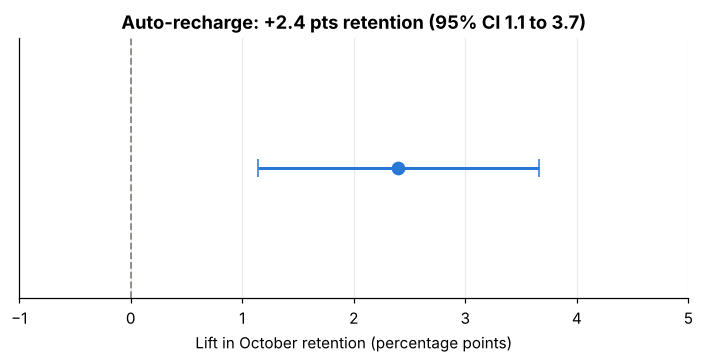

In [12]:
# 5) Was the test big enough? Minimum detectable effect at 80% power, alpha 0.05
p0 = p["control"]; n = g["count"].mean()
mde = (stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) * np.sqrt(2 * p0 * (1 - p0) / n)
need = lambda d: int(np.ceil(2 * p0 * (1 - p0) * (stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) ** 2 / d ** 2))
print(f"With ~{n:,.0f} per arm, the minimum detectable lift was {mde*100:.2f} pts; observed {diff*100:.2f} pts.")
print(f"Sample needed per arm to detect a 1-pt lift: {need(0.01):,}")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.errorbar([diff * 100], [0], xerr=[[diff * 100 - ci[0] * 100], [ci[1] * 100 - diff * 100]], fmt="o", color=BLUE,
            ms=8, capsize=6, lw=2)
ax.axvline(0, color=GREY, ls="--", lw=1.2)
ax.set_yticks([]); ax.set_xlabel("Lift in October retention (percentage points)")
ax.set_title(f"Auto-recharge: +{diff*100:.1f} pts retention (95% CI {ci[0]*100:.1f} to {ci[1]*100:.1f})")
ax.set_xlim(-1, max(5, ci[1] * 100 + 1))
plt.tight_layout(); plt.savefig(IMG / "08_ab_test_result.png", bbox_inches="tight"); plt.show()

**Decision: launch auto-recharge to everyone, and fix mandate failures before or during rollout.**
- The sample split is clean (no sample-ratio mismatch) and the groups were balanced before the test.
- Retention rose by about 2.4 points, statistically significant with a confidence interval well above zero. Across roughly 11,000 monthly operators, that is about 260 extra operators kept each month.
- **Guardrail:** the recharge failure rate rose from 3.4% to 4.3% (+0.9 pts, statistically significant), because auto-debits fail more often than manual recharges (about 5.0% vs 3.5%, bank mandate issues). It's real but small and fixable: retry failed mandates and notify the operator. It shouldn't block the launch, but track it closely during rollout.
- **Caveats:** this is intention-to-treat, so the effect for operators who actually turn the feature on is larger. A single month of follow-up can include a novelty effect, so keep a 5% holdout for 3 months.

## 8. Summary of recommendations

| # | Area | Finding | Action | Metric to watch |
|---|---|---|---|---|
| 1 | Activation | ~1 in 4 signups never submit KYC; worst for paid-ads, single-truck signups | Assisted KYC call-back within 24 h for high-risk segments; test it | KYC submitted within 7 days |
| 2 | Cross-sell | FASTag-only users are half the base but ~7% of revenue; 2+ services churn far less | Target a second service within 60 days of first toll | Monthly multi-service operators (North Star) |
| 3 | Reliability | Bank C outage cut successful recharges ~16% for 2 weeks and lowered retention of hit operators | Failure-rate alerts by bank × region; automatic fallback routing | Failure rate by bank, hourly |
| 4 | Retention | Auto-recharge lifts 30-day retention +2.4 pts (p = 0.0002); failures +0.9 pts | Roll out to all; retry failed mandates; keep a holdout | 30-day retention, auto-debit failure rate |

## 9. Export for Power BI and Excel

In [13]:
out = ROOT / "powerbi"; out.mkdir(exist_ok=True)
fact = act.drop(columns=["mi"]).copy()
fact.to_csv(out / "fact_monthly_activity.csv", index=False)
rd = rc.merge(ops[["operator_id", "city"]], on="operator_id")
rd["date"] = rd.recharge_ts.dt.date
daily_out = (rd.groupby(["date", "bank", "city", "channel", "status"])
               .agg(recharges=("recharge_id", "count"), amount=("amount", "sum")).reset_index())
daily_out.to_csv(out / "fact_recharges_daily.csv", index=False)
funnel.to_csv(out / "onboarding_funnel.csv", index=False)
ops_dim = ops[["operator_id", "signup_ts", "city", "fleet_band", "trucks", "acquisition_channel", "primary_bank"]].copy()
ops_dim["signup_month"] = ops_dim.signup_ts.dt.strftime("%Y-%m")
ops_dim["activated"] = ops_dim.operator_id.isin(ev[ev.stage == "fastag_activated"].operator_id).astype(int)
ops_dim["kyc_submitted"] = ops_dim.operator_id.isin(ev[ev.stage == "kyc_submitted"].operator_id).astype(int)
ops_dim.to_csv(out / "dim_operator.csv", index=False)
cohort_long = ret.stack().rename("retention_pct").reset_index().rename(columns={"level_0": "cohort", "k": "months_since_first"})
cohort_long.to_csv(out / "cohort_retention.csv", index=False)
pd.DataFrame([{"metric": "Control retention", "value": round(p["control"] * 100, 2)},
              {"metric": "Treatment retention", "value": round(p["treatment"] * 100, 2)},
              {"metric": "Lift (pts)", "value": round(diff * 100, 2)},
              {"metric": "95% CI low (pts)", "value": round(ci[0] * 100, 2)},
              {"metric": "95% CI high (pts)", "value": round(ci[1] * 100, 2)},
              {"metric": "p-value", "value": round(pval, 5)},
              {"metric": "Control failure rate (%)", "value": round(fr["control"] * 100, 2)},
              {"metric": "Treatment failure rate (%)", "value": round(fr["treatment"] * 100, 2)}]).to_csv(out / "ab_test_results.csv", index=False)

# Weekly bank x city table for the Excel KPI workbook
rd["week_start"] = (rd.recharge_ts.dt.normalize() - pd.to_timedelta(rd.recharge_ts.dt.weekday, unit="D")).dt.date
wk = (rd[rd.recharge_ts >= "2026-06-29"].groupby(["week_start", "bank", "city"])
        .agg(attempts=("recharge_id", "count"), failed=("status", lambda s: (s == "failed").sum()),
             success_amount=("amount", lambda s: s[rd.loc[s.index, "status"] == "success"].sum())).reset_index())
wk.to_csv(ROOT / "excel" / "weekly_recharges_by_bank_city.csv", index=False)
for f in sorted(out.glob("*.csv")): print(f"{f.name:<28}{sum(1 for _ in open(f)) - 1:>9,} rows")
print("excel/weekly_recharges_by_bank_city.csv", len(wk), "rows")

ab_test_results.csv                 8 rows
cohort_retention.csv               81 rows
dim_operator.csv               40,000 rows
fact_monthly_activity.csv      96,211 rows
fact_recharges_daily.csv       67,196 rows
onboarding_funnel.csv               5 rows
excel/weekly_recharges_by_bank_city.csv 900 rows
